# Exploratory data analysis

[English](01_eda.ipynb) · [简体中文](notebooks/zh-CN/01_eda.ipynb)

Run from a fresh kernel using the deduplicated dataset throughout.


In [1]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from experiment_pipeline import Pipeline
run = Pipeline()
globals().update(run.eda())


Raw file: D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
First 5 rows:


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


Split follows the original CSV row order. Shuffling is confined to Train during fitting.
Reused the feature cache matching the current data and split.
Cache:D:\fujing123\Projects\Data-Analytic\HLR\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
Base features: ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train lexemes:18,353; Validation rows with unseen lexemes:1,150; Test rows with unseen lexemes:560
Reused Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955


# 2. Exploratory figures

The seven figures follow the original notebook. Scan the full file in chunks and use a fixed seed to sample approximately 2% of rows for heavier plots. Frequency statistics in Figures 6 and 7 use the complete dataset.


In [2]:
from collections import Counter
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SAMPLE_FRAC = 0.02
CHUNK_SIZE = 200_000
SAMPLE_SEED = 42
EDA_COLUMNS = [
    "p_recall", "timestamp", "delta", "history_seen", "history_correct",
    "user_id", "lexeme_id", "learning_language", "ui_language",
]
text_dtypes = {
    "user_id": "string", "lexeme_id": "string",
    "learning_language": "string", "ui_language": "string",
}
parts = []
user_counts = Counter()
lexeme_counts = Counter()
pair_counts = Counter()
pair_recall_sums = Counter()
full_p_zero = full_p_one = 0
full_row_count = 0
chunk_count = 0

for chunk_index, chunk in enumerate(pd.read_csv(
    data_path, compression="gzip", chunksize=CHUNK_SIZE,
    usecols=EDA_COLUMNS, dtype=text_dtypes,
)):
    chunk_count += 1
    full_row_count += len(chunk)
    full_p_zero += int(chunk["p_recall"].eq(0).sum())
    full_p_one += int(chunk["p_recall"].eq(1).sum())

    user_counts.update(chunk["user_id"].value_counts().to_dict())
    lexeme_key = chunk["learning_language"].str.cat(chunk["lexeme_id"], sep=":")
    lexeme_counts.update(lexeme_key.value_counts().to_dict())

    pair_chunk = chunk.groupby(
        ["ui_language", "learning_language"], dropna=False
    )["p_recall"].agg(["size", "sum"])
    for pair, stats in pair_chunk.iterrows():
        pair_counts[pair] += int(stats["size"])
        pair_recall_sums[pair] += float(stats["sum"])

    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=SAMPLE_SEED + chunk_index))

eda = pd.concat(parts, ignore_index=True)
eda["delta_days"] = eda["delta"] / 86_400
assert sum(user_counts.values()) == full_row_count
assert sum(lexeme_counts.values()) == full_row_count
assert sum(pair_counts.values()) == full_row_count
print(f"Full file:{full_row_count:,} rows, {chunk_count} chunks")
print(f"EDA sample:{len(eda):,} rows, approximately {len(eda)/full_row_count:.2%}；seed={SAMPLE_SEED}")
print(f"All users:{len(user_counts):,}; all language:lexeme keys:{len(lexeme_counts):,}")
display(eda.head())

Full file:12,854,145 rows, 65 chunks
EDA sample:257,083 rows, approximately 2.00%；seed=42
All users:115,222; all language:lexeme keys:19,279


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,history_seen,history_correct,delta_days
0,1.0,1362088381,228,u:iH0P,es,en,86584daef5933b284384453795bbf0ed,52,47,0.002639
1,1.0,1362086102,613268,u:g47e,it,en,5e27bc0ec9851a23ed650915fc7f50bb,3,2,7.098009
2,1.0,1362090391,270,u:innr,en,pt,a617ed646a251e339738ce62b84e61ce,23,21,0.003125
3,1.0,1362085783,189283,u:iDjx,de,en,5ac6336de0f683c21074570627e9410b,8,6,2.190775
4,1.0,1362084081,2815915,u:gvUe,es,en,edf5a0ef6c836c4df4f3b3de76ca63ba,2,2,32.591609


Fixed `seed=42` selects the same records from the same dataset on every run. `delta_days` is the original interval in seconds divided by 86,400.


## 2.1 Recall proportion


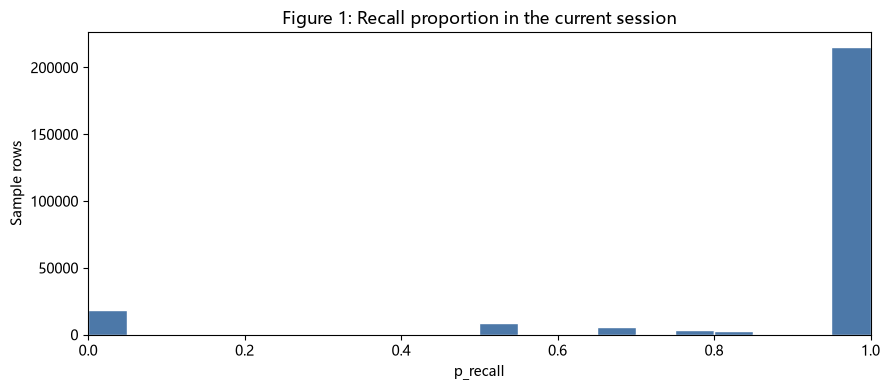

All rows with p_recall=0:906,318（7.05%）
All rows with p_recall=1:10,782,890（83.89%）
All rows with interior p_recall:1,164,937（9.06%）


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(eda["p_recall"], bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="white")
ax.set(xlabel="p_recall", ylabel="Sample rows", title="Figure 1: Recall proportion in the current session")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
print(f"All rows with p_recall=0:{full_p_zero:,}（{full_p_zero/full_row_count:.2%}）")
print(f"All rows with p_recall=1:{full_p_one:,}（{full_p_one/full_row_count:.2%}）")
print(f"All rows with interior p_recall:{full_row_count-full_p_zero-full_p_one:,}（{1-(full_p_zero+full_p_one)/full_row_count:.2%}）")

`p_recall` is strongly concentrated at 1. Model evaluation must account for this distribution when interpreting performance.


## 2.2 Review interval


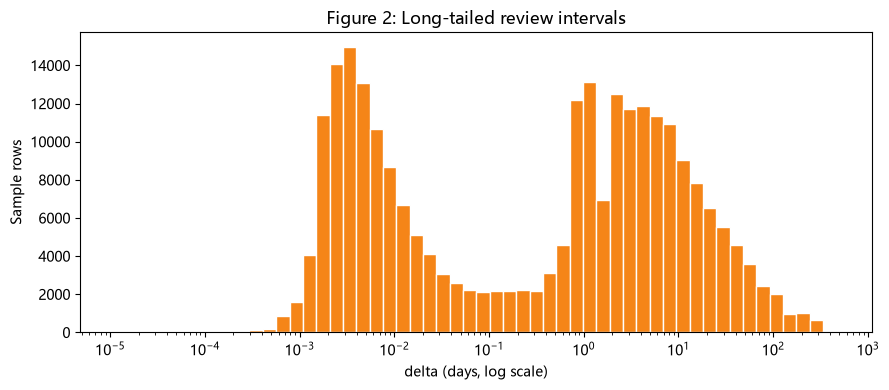

Sample rows with delta=0: 0


0.00      0.000012
0.25      0.006088
0.50      0.892743
0.75      5.125822
0.90     19.899676
0.99    131.834011
1.00    464.945625
Name: delta_days, dtype: float64

In [4]:
positive_days = eda.loc[eda["delta_days"] > 0, "delta_days"]
fig, ax = plt.subplots(figsize=(9, 4))
if len(positive_days):
    log_bins = np.logspace(
        np.log10(positive_days.min()), np.log10(positive_days.max()), 55
    )
    ax.hist(positive_days, bins=log_bins, color="#F58518", edgecolor="white")
    ax.set_xscale("log")
ax.set(xlabel="delta (days, log scale)", ylabel="Sample rows", title="Figure 2: Long-tailed review intervals")
plt.tight_layout()
plt.show()
print("Sample rows with delta=0:", int(eda["delta"].eq(0).sum()))
display(eda["delta_days"].quantile([0, .25, .5, .75, .9, .99, 1]).rename("delta_days"))

Review intervals have a long tail. A logarithmic x-axis shows both short and long intervals.


## 2.3 Historical practice counts


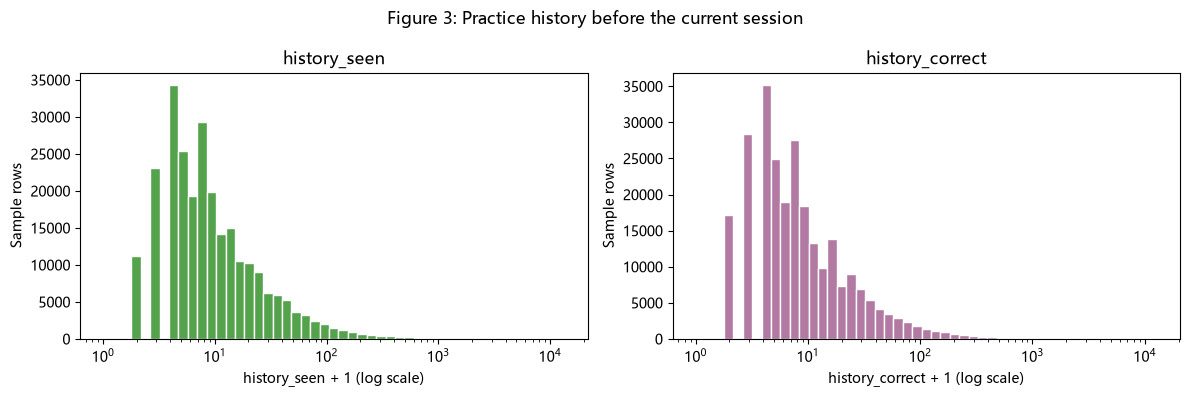

,history_seen,history_correct
0.00,1.0,1.0
0.50,6.0,6.0
0.90,36.0,32.0
0.99,234.0,206.0
1.00,13463.0,12835.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, field, color in zip(
    axes, ["history_seen", "history_correct"], ["#54A24B", "#B279A2"]
):
    values = eda[field].to_numpy() + 1
    bins = np.logspace(0, np.log10(values.max() + 1), 50)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set(xlabel=f"{field} + 1 (log scale)", ylabel="Sample rows", title=field)
plt.suptitle("Figure 3: Practice history before the current session")
plt.tight_layout()
plt.show()
display(eda[["history_seen", "history_correct"]].quantile([0, .5, .9, .99, 1]))

Historical counts also have long tails. The subsequent HLR baselines apply a square-root transformation to the counts.


## 2.4 Review interval and recall


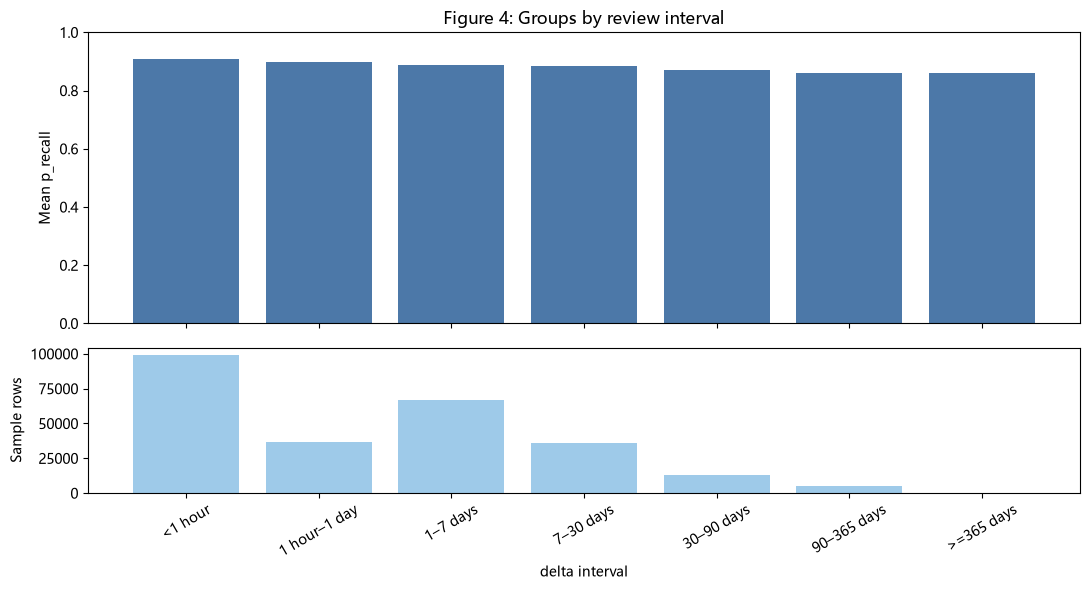

,mean_recall,n
delta_bin,,
<1 hour,0.909624,99494
1 hour–1 day,0.896490,36803
1–7 days,0.888860,67146
7–30 days,0.882713,35953
30–90 days,0.871382,12830
90–365 days,0.858637,4827
>=365 days,0.861111,30


In [6]:
delta_edges = [-np.inf, 1/24, 1, 7, 30, 90, 365, np.inf]
delta_labels = ["<1 hour", "1 hour–1 day", "1–7 days", "7–30 days",
                "30–90 days", "90–365 days", ">=365 days"]
eda["delta_bin"] = pd.cut(
    eda["delta_days"], bins=delta_edges, labels=delta_labels, right=False
)
delta_summary = eda.groupby("delta_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(delta_labels, delta_summary["mean_recall"], color="#4C78A8")
axes[0].set(ylabel="Mean p_recall", ylim=(0, 1), title="Figure 4: Groups by review interval")
axes[1].bar(delta_labels, delta_summary["n"], color="#9ECAE9")
axes[1].set(ylabel="Sample rows", xlabel="delta interval")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(delta_summary)

Group means describe observational associations. Interpret them alongside sample counts, and account for confounding when considering forgetting effects.


## 2.5 Historical practice and recall


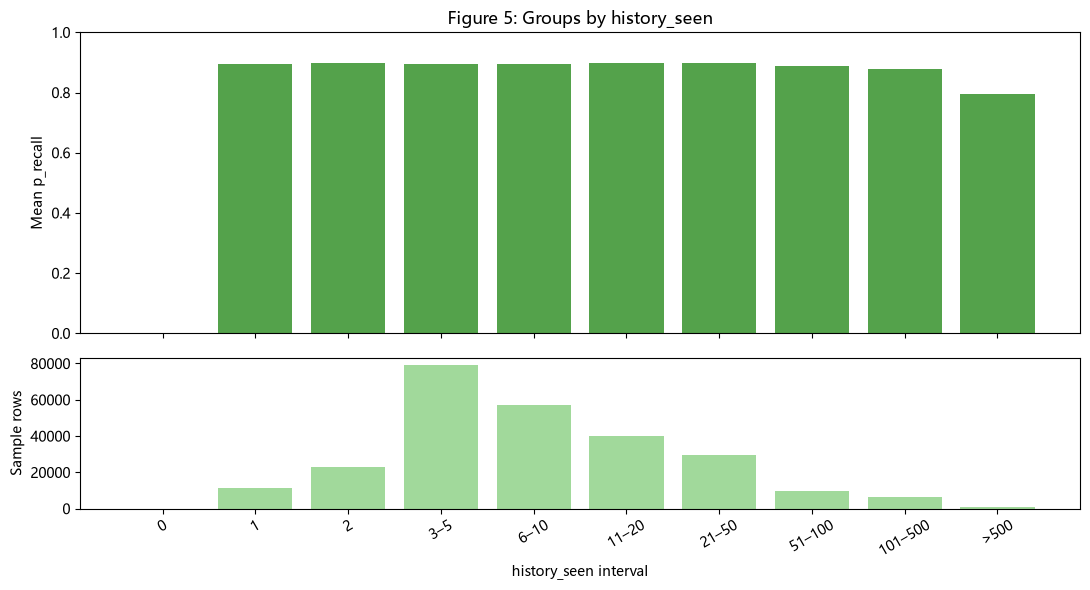

,mean_recall,n
seen_bin,,
0,NaN,0
1,0.893269,11268
2,0.899139,23030
3–5,0.895206,79000
6–10,0.896267,56938
11–20,0.898950,39830
21–50,0.899391,29790
51–100,0.888768,9793
101–500,0.876910,6456


In [7]:
seen_edges = [-1, 0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]
seen_labels = ["0", "1", "2", "3–5", "6–10", "11–20",
               "21–50", "51–100", "101–500", ">500"]
eda["seen_bin"] = pd.cut(
    eda["history_seen"], bins=seen_edges, labels=seen_labels
)
seen_summary = eda.groupby("seen_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(seen_labels, seen_summary["mean_recall"], color="#54A24B")
axes[0].set(ylabel="Mean p_recall", ylim=(0, 1), title="Figure 5: Groups by history_seen")
axes[1].bar(seen_labels, seen_summary["n"], color="#A1D99B")
axes[1].set(ylabel="Sample rows", xlabel="history_seen interval")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(seen_summary)

Recall at different historical practice counts can also reflect learner and item difficulty. Inspect the count in each group.


## 2.6 Language pairs


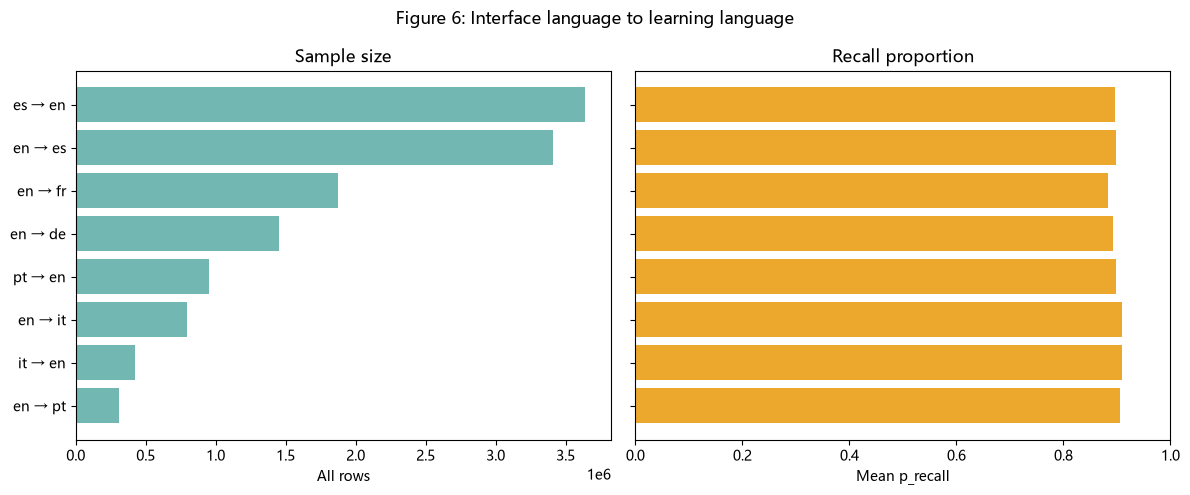

,pair,n,mean_recall
0,en → pt,311480,0.905512
1,it → en,424152,0.909596
2,en → it,793919,0.908592
3,pt → en,949460,0.898728
4,en → de,1452597,0.892786
5,en → fr,1873716,0.882756
6,en → es,3407654,0.898490
7,es → en,3641167,0.896290


In [8]:
pair_summary = pd.DataFrame([
    {
        "ui_language": ui, "learning_language": learning,
        "n": count, "mean_recall": pair_recall_sums[(ui, learning)] / count,
    }
    for (ui, learning), count in pair_counts.items()
]).sort_values("n", ascending=True).reset_index(drop=True)
pair_summary["pair"] = (
    pair_summary["ui_language"] + " → " + pair_summary["learning_language"]
)
positions = np.arange(len(pair_summary))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(positions, pair_summary["n"], color="#72B7B2")
axes[0].set(yticks=positions, yticklabels=pair_summary["pair"],
            xlabel="All rows", title="Sample size")
axes[1].barh(positions, pair_summary["mean_recall"], color="#ECA82C")
axes[1].set(xlabel="Mean p_recall", xlim=(0, 1), title="Recall proportion")
fig.suptitle("Figure 6: Interface language to learning language")
plt.tight_layout()
plt.show()
display(pair_summary[["pair", "n", "mean_recall"]])

Language-pair sample sizes differ substantially. Compare the counts alongside the mean recall rates.


## 2.7 Learner and lexeme frequencies


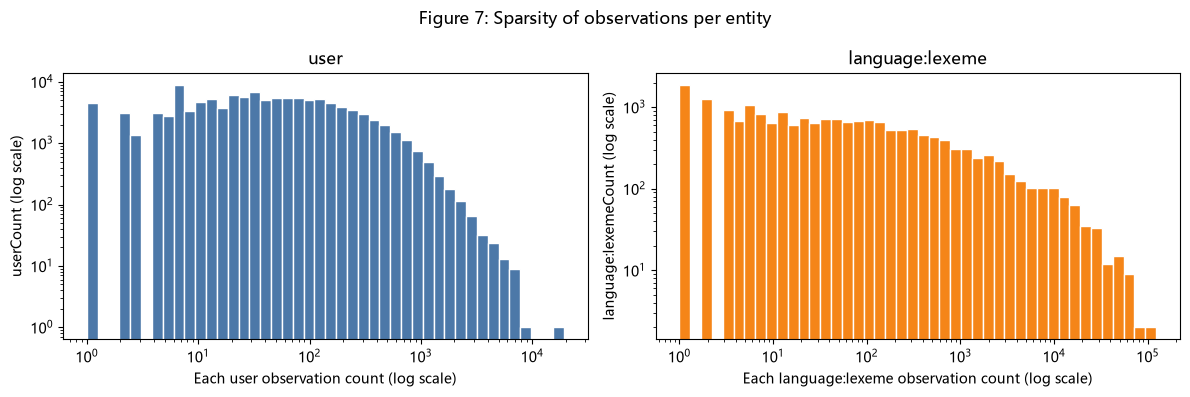

Users:115,222 entities; <=5 observations:11.43%
Language:lexeme keys:19,279 entities; <=5 observations:27.69%


,user_rows,lexeme_rows
0.00,1.00,1.00
0.50,34.00,26.00
0.90,280.00,963.00
0.99,1065.79,13757.08
1.00,19194.00,123098.00


In [9]:
user_frequency = np.fromiter(user_counts.values(), dtype=np.int64)
lexeme_frequency = np.fromiter(lexeme_counts.values(), dtype=np.int64)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, color, label in zip(
    axes,
    [user_frequency, lexeme_frequency],
    ["#4C78A8", "#F58518"],
    ["user", "language:lexeme"],
):
    bins = np.logspace(0, np.log10(values.max() + 1), 45)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(xlabel=f"Each {label} observation count (log scale)",
           ylabel=f"{label}Count (log scale)", title=label)
plt.suptitle("Figure 7: Sparsity of observations per entity")
plt.tight_layout()
plt.show()
print(f"Users:{len(user_frequency):,} entities; <=5 observations:{np.mean(user_frequency <= 5):.2%}")
print(f"Language:lexeme keys:{len(lexeme_frequency):,} entities; <=5 observations:{np.mean(lexeme_frequency <= 5):.2%}")
display(pd.DataFrame({
    "user_rows": pd.Series(user_frequency).quantile([0, .5, .9, .99, 1]),
    "lexeme_rows": pd.Series(lexeme_frequency).quantile([0, .5, .9, .99, 1]),
}))

Many learners and lexemes are infrequent. Full HLR uses only the three base features for lexemes unseen in Train.
